In [14]:
# Cell 1 - Paths and list of processed files
from pathlib import Path
import gzip
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

project_dir = Path(r"C:\Users\ADMIN\Documents\human-blastoid-scrna")
processed   = project_dir / "data" / "processed"
out_dir     = project_dir / "data" / "embryo_ref_upload"   # files for the web tool (inside data/, never on GitHub)
out_dir.mkdir(parents=True, exist_ok=True)

for f in sorted(processed.glob("*.h5ad")):
    print(f.name, round(f.stat().st_size / 1e6), "MB")

D14_cells.h5ad 181 MB
D14_qc.h5ad 166 MB
D21_cells.h5ad 210 MB
D21_qc.h5ad 203 MB
D7_cells.h5ad 194 MB
D7_qc.h5ad 184 MB
merged_annotated.h5ad 346 MB
merged_annotated_v2.h5ad 346 MB
merged_normalized.h5ad 318 MB
merged_umap.h5ad 324 MB


In [3]:
# Cell 2 - Inspect the candidate files without loading the full matrices
for name in ["merged_annotated_v2.h5ad", "D7_qc.h5ad"]:
    a = sc.read_h5ad(processed / name, backed="r")       # read-only, matrix stays on disk
    print("=====", name)
    print("cells x genes :", a.shape)
    print("layers        :", list(a.layers.keys()))
    print("has .raw      :", a.raw is not None)
    print("obs columns   :", a.obs.columns.tolist()[:15])
    print("first cells   :", a.obs_names[:3].tolist())
    a.file.close()                                        # release the file

===== merged_annotated_v2.h5ad
cells x genes : (13240, 36601)
layers        : ['counts']
has .raw      : False
obs columns   : ['total_counts', 'timepoint', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'doublet_score', 'scrublet_called', 'high_doublet_score', 'leiden_r03', 'leiden_r05', 'leiden_r08', 'cell_state', 'flag_transitional_cluster', 'leiden_r05_sub']
first cells   : ['AAACCCACAAAGCTCT-1_D7', 'AAACCCAGTGTTTGCA-1_D7', 'AAACCCATCAGAGCGA-1_D7']
===== D7_qc.h5ad
cells x genes : (4540, 36601)
layers        : []
has .raw      : False
obs columns   : ['total_counts', 'timepoint', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt']
first cells   : ['AAACCCACAAAGCTCT-1', 'AAACCCAGTGTTTGCA-1', 'AAACCCATCAGAGCGA-1']


In [4]:
# Cell 2b - Load the chosen file fully (Cells 3-4 need the matrix in memory)
adata = sc.read_h5ad(processed / "merged_annotated_v2.h5ad")
print(adata.shape)
print(adata.obs["sample"].value_counts())    # sample names used in Cell 4

(13240, 36601)
sample
D21    5454
D7     4540
D14    3246
Name: count, dtype: int64


In [12]:
# Cell 3 - Pick the raw-count matrix and check it really contains integers
def looks_like_counts(m):
    v = m.data if sp.issparse(m) else np.asarray(m).ravel()
    v = v[:200000]                                   # a sample of the values is enough
    return np.allclose(v, np.round(v)) and v.min() >= 0

if "counts" in adata.layers and looks_like_counts(adata.layers["counts"]):
    counts, source = adata.layers["counts"], "layers['counts']"
elif looks_like_counts(adata.X):
    counts, source = adata.X, "X"
else:
    raise ValueError("No raw-count matrix found in this file - choose another .h5ad")

print("raw counts taken from:", source, "| shape:", counts.shape)

raw counts taken from: layers['counts'] | shape: (13240, 36601)


In [7]:
# Cell 4 - Write one gzip TSV per sample: genes in rows, cells in columns, first column "Gene"
def export_sample(sample, chunk=2000):
    mask = (adata.obs["sample"] == sample).values
    m = sp.csc_matrix(counts[mask])                  # cells x genes, column access is fast
    detected = np.asarray((m > 0).sum(axis=0)).ravel() > 0
    genes = adata.var_names[detected]
    m = m[:, detected]
    cells = adata.obs_names[mask]

    path = out_dir / f"{sample}_raw_counts.tsv.gz"
    with gzip.open(path, "wt") as fh:
        fh.write("Gene\t" + "\t".join(cells) + "\n")               # header line
        for start in range(0, len(genes), chunk):                   # write 2,000 genes at a time to save RAM
            block = m[:, start:start + chunk].toarray().T.astype(np.int32)
            pd.DataFrame(block, index=genes[start:start + chunk]).to_csv(fh, sep="\t", header=False)
    pd.Series(cells, name="cell").to_csv(out_dir / f"{sample}_cells.csv", index=False)   # cell names, to join results later
    print(sample, "->", path.name, "|", len(cells), "cells,", len(genes), "genes,",
          round(path.stat().st_size / 1e6, 1), "MB")

for s in ["D7", "D14", "D21"]:          # change if your sample names differ (see Cell 2)
    export_sample(s)

D7 -> D7_raw_counts.tsv.gz | 4540 cells, 25504 genes, 20.1 MB
D14 -> D14_raw_counts.tsv.gz | 3246 cells, 29873 genes, 19.4 MB
D21 -> D21_raw_counts.tsv.gz | 5454 cells, 30824 genes, 24.0 MB


In [10]:
# Cell 5 - Check the first lines of one exported file
check = pd.read_csv(out_dir / "D7_raw_counts.tsv.gz", sep="\t", nrows=5, index_col=0)
print(check.index.name, check.shape)      # index name must be 'Gene'
print(check.iloc[:, :4])                  # integers only

Gene (5, 4540)
            AAACCCACAAAGCTCT-1_D7  AAACCCAGTGTTTGCA-1_D7  \
Gene                                                       
AL627309.1                      0                      0   
AL627309.5                      0                      0   
AL627309.4                      0                      0   
AL732372.1                      0                      0   
LINC01409                       0                      0   

            AAACCCATCAGAGCGA-1_D7  AAACCCATCATCACAG-1_D7  
Gene                                                      
AL627309.1                      0                      0  
AL627309.5                      0                      0  
AL627309.4                      0                      0  
AL732372.1                      0                      0  
LINC01409                       0                      0  


In [17]:
# Cell 6 - Peek at the three files downloaded for D7
ref_dir = project_dir / "Result" / "embryo_ref"
for kind in ["annotation", "umap", "cellgroup"]:
    df = pd.read_csv(ref_dir / f"zhao_D7_{kind}.tsv", sep="\t")
    print("=====", kind, df.shape)
    print(df.columns.tolist())
    print(df.head(3), "\n")

===== annotation (4540, 6)
['query_cell', 'pred_EML', 'sub_pred_EML', 'stage', 'prediction_score_max', 'pred_psdt']
              query_cell  pred_EML sub_pred_EML  stage  prediction_score_max  \
0  AAACCCACAAAGCTCT-1_D7        TE           TE  Early              0.985357   
1  AAACCCAGTGTTTGCA-1_D7  Epiblast    Early_EPI  Early              0.967021   
2  AAACCCATCAGAGCGA-1_D7        TE           TE  Early              0.992727   

   pred_psdt  
0  13.395942  
1  12.681881  
2  14.172177   

===== umap (3760, 6)
['cell', 'UMAP_2', 'UMAP_1', 'devTime', 'EML', 'pj']
                    cell    UMAP_2    UMAP_1 devTime        EML     pj
0  AAACCCATCATCACAG-1_D7 -2.225877 -2.653659     NaN  Early_EPI  query
1  AAACGAAGTTGTATGC-1_D7 -2.402815 -2.495302     NaN  Early_EPI  query
2  AAACGCTGTTGCCGAC-1_D7 -1.903067 -3.121680     NaN  Early_EPI  query 

===== cellgroup (13644, 2)
['Scell', 'Hcell']
                   Scell                  Hcell
0  AAACCCATCATCACAG-1_D7  AAACCCATCATCACAG-1_D7

In [18]:
# Cell 7 - Cross-tabulate my labels against the reference-tool predictions
labels = pd.read_csv(project_dir / "Result" / "cell_state_v3_labels.csv", index_col=0)
print("label columns:", labels.columns.tolist())
label_col = next((c for c in labels.columns if "v3" in c or "state" in c), labels.columns[0])
print("using column :", label_col)

def compare(sample):
    pred = pd.read_csv(ref_dir / f"zhao_{sample}_annotation.tsv", sep="\t").set_index("query_cell")
    both = pred.join(labels[[label_col]], how="inner")                 # keep cells present in both tables
    print(sample, "| cells matched:", len(both), "of", len(pred))
    counts = pd.crosstab(both[label_col], both["pred_EML"], margins=True, margins_name="Total")
    pct = (pd.crosstab(both[label_col], both["pred_EML"], normalize="index") * 100).round(1)
    counts.to_csv(ref_dir / f"crosstab_{sample}_counts.csv")
    pct.to_csv(ref_dir / f"crosstab_{sample}_percent.csv")
    return both, counts, pct

both_D7, counts_D7, pct_D7 = compare("D7")
pd.set_option("display.width", 250)
print(counts_D7)
print(pct_D7)

label columns: ['sample', 'leiden_r05', 'leiden_r05_sub', 'leiden_r05_sub13', 'cell_state_v2', 'cell_state_v3', 'exclude_default']
using column : cell_state_v2
D7 | cells matched: 4540 of 4540
pred_EML                        Ambiguous  Epiblast  Hypoblast    TE  nb_failed  Total
cell_state_v2                                                                         
Epiblast-like (TE-primed, D7)          28       333          2    59         43    465
Epiblast-like (bEPI, D14/D21)           0         0          0     0          1      1
Epiblast-like (bEPI, D7)               62      1723          0     0        105   1890
Polar TE-like (bPolarTE)                9         0          0    73         20    102
Primitive endoderm-like (bPE)          13        57         31     5         10    116
Probable doublets (EPI/TE, D7)          0        15          0    65          8     88
TE-like (bTE)                           6        10          0  1678        184   1878
Total                   

In [19]:
# Cell 8 - Run the comparison for every sample (Cell 7 must have been run once in this session)
results = {}
for s in ["D7", "D14", "D21"]:
    both, counts, pct = compare(s)
    results[s] = both                       # keep the merged table of each sample for later plots
    print(counts, "\n")
    print(pct, "\n")

D7 | cells matched: 4540 of 4540
pred_EML                        Ambiguous  Epiblast  Hypoblast    TE  nb_failed  Total
cell_state_v2                                                                         
Epiblast-like (TE-primed, D7)          28       333          2    59         43    465
Epiblast-like (bEPI, D14/D21)           0         0          0     0          1      1
Epiblast-like (bEPI, D7)               62      1723          0     0        105   1890
Polar TE-like (bPolarTE)                9         0          0    73         20    102
Primitive endoderm-like (bPE)          13        57         31     5         10    116
Probable doublets (EPI/TE, D7)          0        15          0    65          8     88
TE-like (bTE)                           6        10          0  1678        184   1878
Total                                 118      2138         33  1880        371   4540 

pred_EML                        Ambiguous  Epiblast  Hypoblast    TE  nb_failed
cell_state_v2  

In [20]:
# Cell 9 - Repeat the comparison with the final labels (cell_state_v3)
label_col = "cell_state_v3"
results = {s: compare(s)[0] for s in ["D7", "D14", "D21"]}

changed = labels[labels["cell_state_v2"] != labels["cell_state_v3"]]          # cells whose label changed
print("cells with a different v2/v3 label:", len(changed))
print(pd.crosstab(changed["cell_state_v2"], changed["cell_state_v3"]))

D7 | cells matched: 4540 of 4540
D14 | cells matched: 3246 of 3246
D21 | cells matched: 5454 of 5454
cells with a different v2/v3 label: 1596
cell_state_v3                  Advanced mesoderm-like (bAdMes)  Extraembryonic mesoderm-like (bExMes)  Mesenchyme-like (mixed)
cell_state_v2                                                                                                                 
Mesoderm-like (bAdMes/bExMes)                              512                                    573                      511


In [22]:
# Cell 10 - Agreement between my labels (cell_state_v3) and the reference predictions
expected_rules = [                                   # checked in this order; first match wins
    ("doublet", None), ("Unresolved", None),          # flagged cells: not evaluated
    ("Primitive syncytium", {"STB"}),
    ("Polar TE", {"TE"}),
    ("Primitive endoderm", {"Hypoblast", "YSE", "DE"}),
    ("Endoderm", {"Hypoblast", "YSE", "DE"}),
    ("Epiblast", {"Epiblast"}),
    ("CTB", {"CTB", "TE"}),
    ("EVT", {"EVT"}),
    ("ST-like", {"STB"}),
    ("Primitive streak", {"PriS", "Mesoderm", "AdvMes"}),
    ("Mesenchyme", {"AdvMes", "ExE_Mes", "Mesoderm"}),
    ("Mesoderm", {"AdvMes", "ExE_Mes", "Mesoderm"}),
    ("Amnion", {"Amnion"}),
    ("TE-like", {"TE"}),
]
not_assigned = {"Ambiguous", "nb_failed", "low_cor"}  # the tool gave no clear label

def expected(label):
    for key, exp in expected_rules:
        if key.lower() in label.lower():
            return exp
    return None

rows, overall = [], []
for s, both in results.items():
    b = both.copy()
    b["expected"] = b[label_col].map(expected)
    b["assigned"] = ~b["pred_EML"].isin(not_assigned)
    b["match"] = [e is not None and p in e for p, e in zip(b["pred_EML"], b["expected"])]
    for lab, g in b.groupby(label_col):
        exp = g["expected"].iloc[0]
        n_as = g["assigned"].sum()
        rows.append({"sample": s, "my_label": lab, "n_cells": len(g),
                     "expected": " / ".join(sorted(exp)) if exp else "not evaluated (flagged)",
                     "pct_unassigned": round(100 * (1 - g["assigned"].mean()), 1),
                     "pct_match_of_assigned": round(100 * g["match"].sum() / n_as, 1) if exp and n_as else np.nan})
    ev = b[b["expected"].notna() & b["assigned"]]                 # evaluated cells only
    overall.append({"sample": s, "cells_evaluated": len(ev),
                    "pct_match": round(100 * ev["match"].mean(), 1)})

agree = pd.DataFrame(rows)
agree_sample = pd.DataFrame(overall)
agree.to_csv(ref_dir / "agreement_by_label.csv", index=False)
agree_sample.to_csv(ref_dir / "agreement_by_sample.csv", index=False)
pd.set_option("display.width", 250)
print(agree.to_string())
print(agree_sample)

   sample                                                    my_label  n_cells                     expected  pct_unassigned  pct_match_of_assigned
0      D7                               Epiblast-like (TE-primed, D7)      465                     Epiblast            15.3                   84.5
1      D7                               Epiblast-like (bEPI, D14/D21)        1                     Epiblast           100.0                    NaN
2      D7                                    Epiblast-like (bEPI, D7)     1890                     Epiblast             8.8                  100.0
3      D7                                    Polar TE-like (bPolarTE)      102                           TE            28.4                  100.0
4      D7                               Primitive endoderm-like (bPE)      116         DE / Hypoblast / YSE            19.8                   33.3
5      D7                              Probable doublets (EPI/TE, D7)       88      not evaluated (flagged)           

In [23]:
# Cell 10b - Do bAdMes / bExMes / mixed mesenchyme map to AdvMes / ExE_Mes in the reference?
d21 = results["D21"]
meso = d21[d21[label_col].str.contains("mesoderm|Mesenchyme", case=False)]      # mesoderm-type labels only
meso_pct = (pd.crosstab(meso[label_col], meso["pred_EML"], normalize="index") * 100).round(1)
meso_pct.to_csv(ref_dir / "crosstab_D21_mesoderm_v3_percent.csv")
print(meso_pct.to_string())

pred_EML                                   AdvMes  Ambiguous  Amnion   CTB   DE   EVT  Epiblast  ExE_Mes  HEP  Hypoblast  Mesoderm  PriS  STB  low_cor  nb_failed
cell_state_v3                                                                                                                                                    
Advanced mesoderm-like (bAdMes)              25.0        3.9     0.0   0.2  0.2   0.2       0.0     63.4  0.2        0.2       0.0   0.0  0.0      0.0        6.7
Extraembryonic mesoderm-like (bExMes)         0.2        0.2     0.0   0.0  0.0   0.0       0.0     88.7  0.0        0.0       0.0   0.0  0.0      1.9        9.1
Mesenchyme-like (mixed)                       6.5        2.8     0.0   0.0  0.2   0.0       0.0     74.9  6.1        0.0       0.0   0.0  0.0      0.0        9.6
Mesoderm-like (intermediate)                  0.0        0.0     0.0  11.5  0.0  50.4       0.0     15.1  0.0        5.8       0.0   0.0  0.0      0.0       17.3
Primitive streak / emergent 

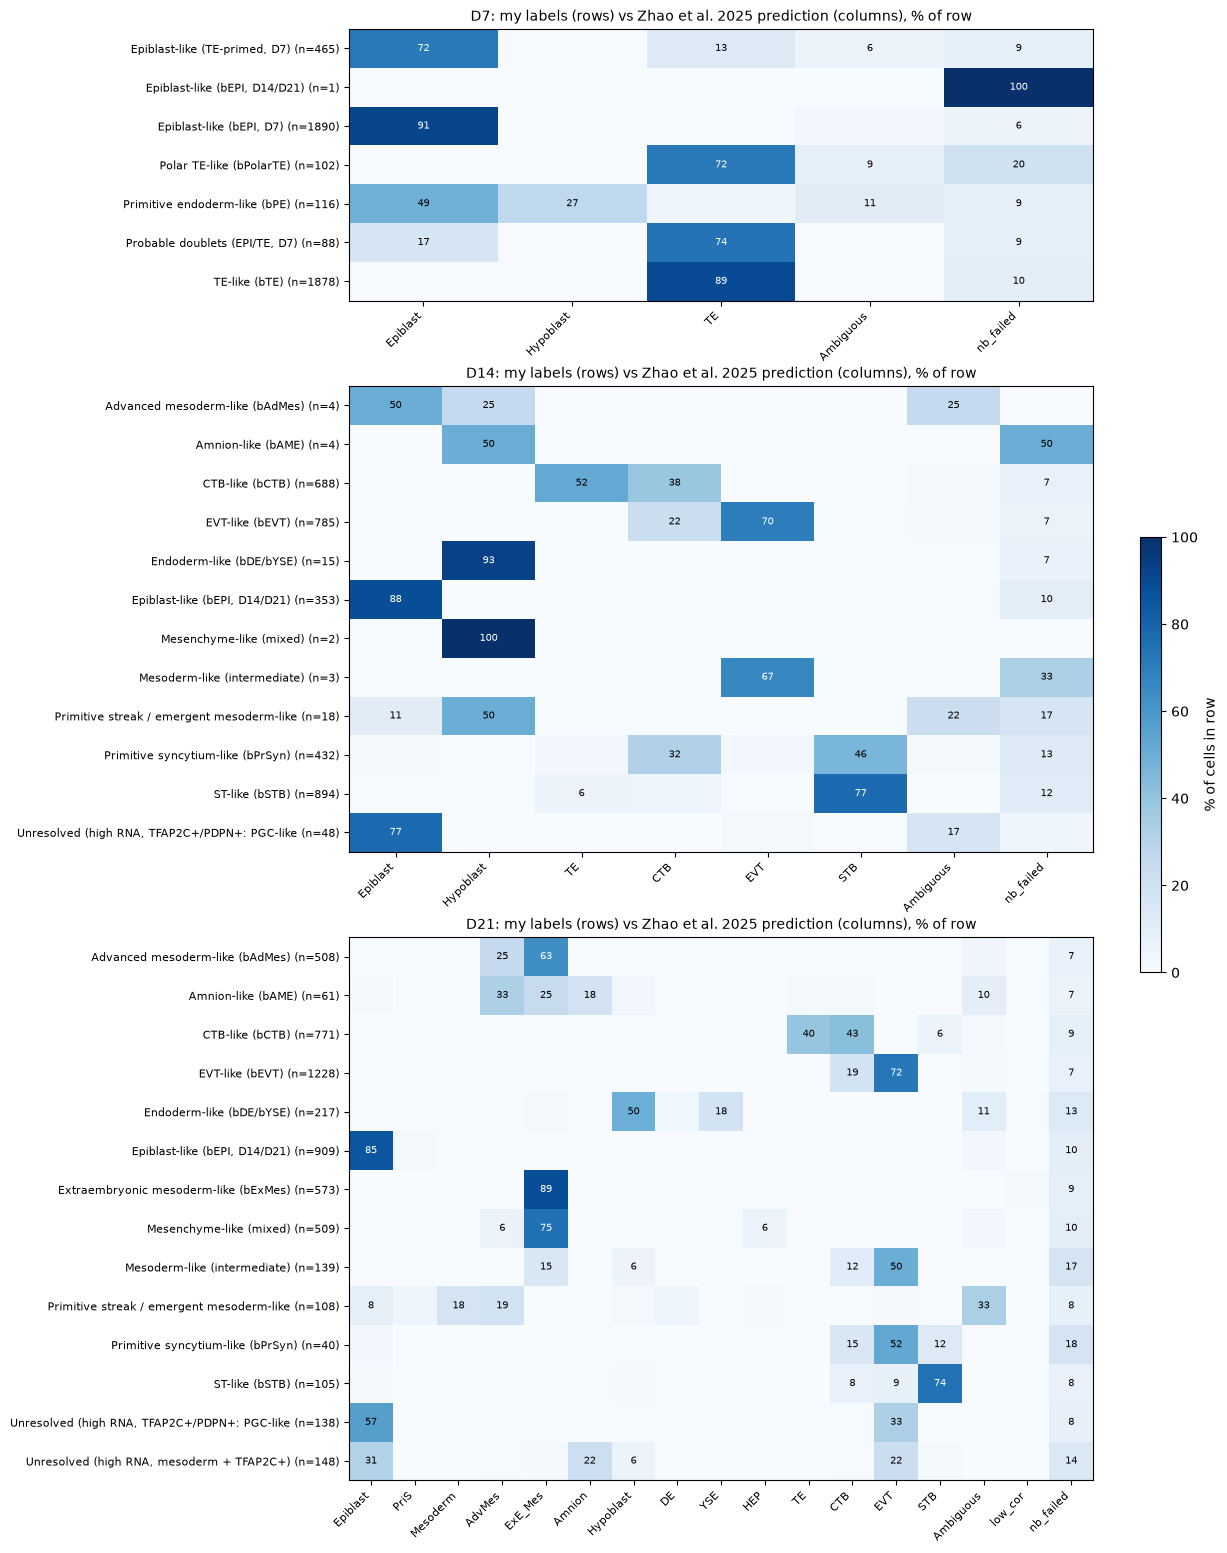

In [24]:
# Cell 11 - Heatmap: my labels (rows) vs reference predictions (columns), % of each row
import matplotlib.pyplot as plt

col_order = ["Epiblast", "PriS", "Mesoderm", "AdvMes", "ExE_Mes", "Amnion", "Hypoblast", "DE", "YSE", "HEP",
             "TE", "CTB", "EVT", "STB", "Ambiguous", "low_cor", "nb_failed"]
samples = ["D7", "D14", "D21"]
heights = [results[s][label_col].nunique() for s in samples]          # panel height = number of labels

fig, axes = plt.subplots(3, 1, figsize=(12, 0.45 * sum(heights) + 4), gridspec_kw={"height_ratios": heights})
for ax, s in zip(axes, samples):
    b = results[s]
    pct = pd.crosstab(b[label_col], b["pred_EML"], normalize="index") * 100
    pct = pct.reindex(columns=[c for c in col_order if c in pct.columns])
    n = b[label_col].value_counts()
    im = ax.imshow(pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(pct.shape[1]))
    ax.set_xticklabels(pct.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(pct.shape[0]))
    ax.set_yticklabels([f"{lab[:45]} (n={n[lab]})" for lab in pct.index], fontsize=8)
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            v = pct.values[i, j]
            if v >= 5:                                                   # print only values of 5% or more
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if v > 60 else "black")
    ax.set_title(f"{s}: my labels (rows) vs Zhao et al. 2025 prediction (columns), % of row", fontsize=10)

fig.colorbar(im, ax=axes, shrink=0.3, label="% of cells in row")
fig.savefig(project_dir / "Figure" / "embryo_ref_crosstab_v3.png", dpi=200, bbox_inches="tight")
plt.show()